# Ji et al. 2020 — Cutaneous SCC · 06 Expression

EMT-transcription-factor expression overlaid on the manifold (unconditional final step). The panel is chosen by detectable expression on this dataset from a candidate set spanning Snail/Zeb/Twist **and** FOXC/PRRX families (Kürten lesson). Categorical overlay of thresholded expressers on the developmental manifold, reference style.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)

### Load manifold (developmental compartment, with pseudotime + milestones)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad')); adata

AnnData object with n_obs × n_vars = 6800 × 1443
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'leiden', 'GSE162534', 'GSE229103', 'rRNAModifications', 'GSE162534_sm', 'GSE229103_sm', 'rRNAModifications_sm', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### EMT-TF panel selection
Score each candidate EMT-TF by detection fraction and pseudotime trend across the manifold. On this 10x cSCC, **SNAI2** (SLUG) is the dominant expressed factor (late/terminal, the canonical neural-crest EMT-TF, coherent with the Crest-high leading edge); **PRRX2** is the best-detected root/early-leaning mesenchymal factor. Canonical SNAI1/ZEB1/TWIST sit near the 10x dropout floor. VIM is a mesenchymal marker, **not** a TF, and is excluded.

In [4]:
cand = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
raw = adata.raw.to_adata(); raw.obs = adata.obs
present = [g for g in cand if g in raw.var_names]
rows = []
for g in present:
    x = np.asarray(raw[:, g].X.todense()).ravel()
    rows.append((g, round((x>0).mean()*100,1), round(spearmanr(x, adata.obs.t)[0],3)))
import pandas as pd
tab = pd.DataFrame(rows, columns=['TF','det%','rho_pt']).sort_values('det%', ascending=False)
print(tab.to_string(index=False))

    TF  det%  rho_pt
 SNAI2  50.5   0.337
 PRRX2   9.0  -0.026
 FOXC1   4.0  -0.039
 SNAI1   2.1  -0.034
  ZEB2   2.1  -0.013
  ZEB1   0.8   0.030
 PRRX1   0.3   0.026
TWIST1   0.2   0.005
TWIST2   0.1   0.016
 FOXC2   0.0   0.014


### EMT-TF expression overlay

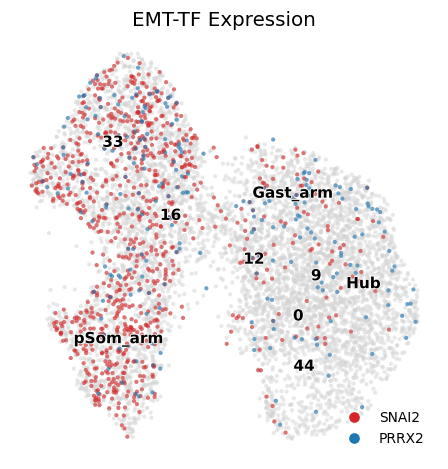

In [5]:
# threshold each TF near its detection floor; overlay expressers coloured on the grey manifold
g_plt = {'SNAI2': ('tab:red', 1.0), 'PRRX2': ('tab:blue', 0.5)}
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 30, alpha = .5, frameon = False, show = False, ax = ax)
for var, (c, thresh) in g_plt.items():
    sub = raw[np.asarray(raw[:, var].X.todense()).ravel() > thresh].copy()
    sub.obsm['X_umap'] = adata[sub.obs_names].obsm['X_umap']
    sc.pl.umap(sub, na_color = c, size = 30, alpha = .6, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'milestones', size = 30, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=8, label=v) for v,(c,_) in g_plt.items()]
ax.legend(handles=handles, loc='lower right', frameon=False, fontsize=9)
ax.set_title('EMT-TF Expression', size = 13)
fig.savefig(os.path.join(pth_out, 'expression.pdf'), bbox_inches = 'tight')